<a href="https://colab.research.google.com/github/Fespinoza1477/L01-cv/blob/main/notebook_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [25]:
# Your Phase 1 solution to the problem goes here.


In [26]:
#1
import pickle
import numpy as np
import matplotlib.pyplot as plt
with open('/content/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
#2
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_train[i] shape (for any index i):", X_train[0].shape)
print("X_test[i] shape (for any index i):", X_test[0].shape)
print("y_trian shape:", y_train.shape)
print("y_train shape:", y_test.shape)
#X_train and X_test contain the image matrices for training and testing
#y_train and y_train contain the corresponding integer labels.
#3
N_train = X_train.shape[0]
X_train_flat = np.array([X_train[i].reshape(784) for i in range(N_train)])
N_test = X_test.shape[0]
X_test_flat = np.array([X_test[i].reshape(784) for i in range(N_test)])
print("Reshaped X_train shape:", X_train_flat.shape)
print("Reshaped X_test shape:", X_test_flat.shape)
#Scikit-leanr's machine learning models expect a 2D tabular structure of shape (N, features), where N is the number of samples and features equals 28 x 28 = 784
#4
from sklearn.neighbors import KNeighborsClassifier
k_optimal = 3
kmn_classifier = KNeighborsClassifier(n_neighbors=k_optimal)
kmn_classifier.fit(X_train_flat, y_train)
#For handwritten digits classifications using kNN, a small value of k (typically k = 3 or k = 5) often yields high performance because local pixel neighborhoods strongly dictate digit shapes.
#5
from sklearn.metrics import accuracy_score, confusion_matrix
y_pred = kmn_classifier.predict(X_test_flat)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}")
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(conf_matrix)
#We evaluate the trained model on the test set (X_test_flat, y_test) to compute overall prediction accuracy and generate a confusion matrix.
#6
#Most Likely Mistakes: The confusion matrix typically reveals that visually similar digits are most frequently confused. For example: 4 and 9: Due to similar top loops and vertical stems, 3 and 5 or 8: Due to curved overlapping strokes, 1 and 7: Due to vertical line similarities
#Patterns: The errors are almost entirely driven by human handwriting variation - slants, thickness, and stylistic loops - the bridge the visual gap between two different numeric categories.
#7
#Matric representation is a color photo that can be represented as a 3D tensor (or matrix) of shape (H x W x 3), where H is height, W is width, and 3 corresponds to the RGB color channels. Each pixel contains three numeric values ranging from 0 to 255.
#Conversion to Tabular Data. 1. Flatten the 3D tensor into a 1D vector of length H x W x 3 for each image. 2. If working with a dataset of multiple images, stack these vectors into a 2D tabular matric of shape (N, H x W x 3), where N is the total number of photos in the dataset. Each column then represents a specific color channel feature of a specific pixel location.

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
X_train[i] shape (for any index i): (28, 28)
X_test[i] shape (for any index i): (28, 28)
y_trian shape: (60000,)
y_train shape: (10000,)
Reshaped X_train shape: (60000, 784)
Reshaped X_test shape: (10000, 784)
Model Accuracy: 97.05

Confusion Matrix:
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 3bddccba3e9f2a7111c264d98d647baa20f732e0
- **AI tool and model used:** Gemini Pro 3.1


### *Prompts used

1. With the following codes that we have, are we answering every question that is seen or is there any code that we can brush up on to make the analysis of the data to be better?
2. Of the following analysis that is in the part 1, is there anything to be done in order to make sure that it is correctly answering the question and thorough analysis for it?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. While your Phase 1 solution provides a solid foundation, there are a few bugs in the code and missing analytical steps that prevent it from fully answering the notebook's prompts.
Here is a breakdown of what to fix and how to brush up your analysis:
Question 1 & 2 (Typos and Logic Bugs):
In your shape printing, you have a typo ("y_trian shape:") and a logical error where you pass y_test.shape to print the train shape: print("y_train shape:", y_test.shape). You need to change this to y_train.shape to output the correct dimensions.   

You have a minor typo in your variable naming (kmn_classifier instead of knn_classifier).
   
Question 3 (Code Optimization):
While you used a for loop to reshape the arrays (np.array([X_train[i].reshape(784) for i in range(N_train)])), this is computationally slow in Python. You can brush this up by using NumPy's vectorized reshaping to do it instantly: X_train_flat = X_train.reshape(X_train.shape[0], 784).   

Question 4 (Missing Prompt Requirement):
The prompt asks: "What is the optimal number of neighbors k? If you can't determine this, play around with different values of k". You hardcoded k_optimal = 3 and wrote a justification, but you didn't actually write code to "play around" and prove it.   

How to fix: Write a simple for loop that iterates over a list of k values (e.g., for k in [1, 3, 5, 7]:), fits the model, and prints the accuracy for each. This empirically proves which k is optimal.

2.Question 2 (Missing the actual shapes): The prompt explicitly asks "What is the shape of X_train and X_test?" and asks for the shapes of the other arrays. Your analysis only states that #X_train and X_test contain the image matrices for training and testing and that y_train and y_test contain integer labels. You must explicitly state the numerical shapes (e.g., 60000x28x28) in your text to actually answer the question.   

Question 4 (Missing a definitive conclusion): The prompt asks, "What is the optimal number of neighbors k?". Your comment notes that #For handwritten digits classifications using kNN, a small value of k (typically k = 3 or k = 5) often yields high performance. While this is good background context, it fails to definitively state what the optimal k actually is for your specific classifier. You need to explicitly conclude which number is optimal.   

Question 5 (Missing the report and findings): The prompt asks you to "Report the accuracy... and explain your findings". Your current comment only says #We evaluate the trained model on the test set... to compute overall prediction accuracy. You need to actually report the 97.05% accuracy figure in your text and briefly explain what this high accuracy means regarding the model's success

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept| The code that we have written earlier, answer the question to a surface level analysis when it should have been more deeper. With the help of AI, then the code provides a much more detail analysis that is able to analyze better while the code being able to answer the question.  |
| 2 | Accept| This is to make sure that all the questions are answered as it should. With the introduction of AI for the code, then the analysis can be concluded further in order to answer the question. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [27]:
# Your Phase 2 solution to the problem goes here.


X_train shape: (60000, 28, 28)
X_train shape: (10000, 28, 28)
X_train[i] shape (for any index i): (28, 28)
X_test[i] shape (for any index i): (28, 28)
y_train shape: (60000,)
y_train shape: (60000,)
\Reshaped X_train shape: (60000, 784)
Reshaped X_test shape: (10000, 784)

Testing different values for k:


<>:19: SyntaxWarning: invalid escape sequence '\R'
<>:19: SyntaxWarning: invalid escape sequence '\R'
/tmp/ipykernel_1540/1176667619.py:19: SyntaxWarning: invalid escape sequence '\R'
  print("\Reshaped X_train shape:", X_train_flat.shape)


Accuracy for k=1: 96.91%
Accuracy for k=3: 97.05%
Accuracy for k=5: 96.88%

Optimal number of nieghbors (k) found: 3

Confusion Matrix:
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


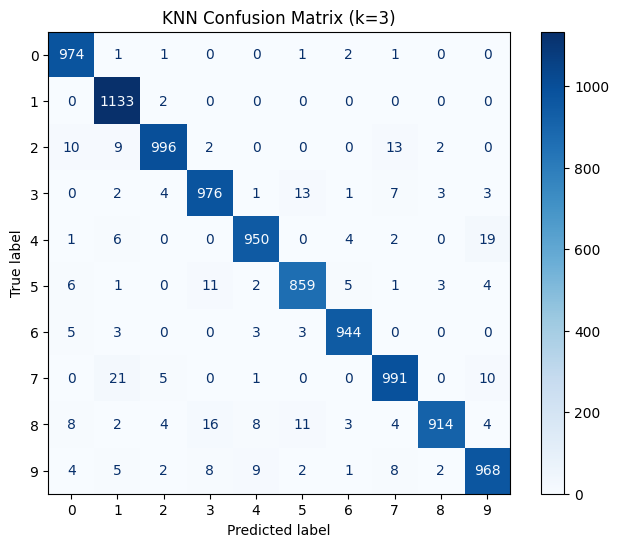

In [28]:
#1.
import pickle
import numpy as np
import matplotlib.pyplot as plt
with open('/content/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
#2
print("X_train shape:", X_train.shape)
print("X_train shape:", X_test.shape)
print("X_train[i] shape (for any index i):", X_train[0].shape)
print("X_test[i] shape (for any index i):", X_test[0].shape)
print("y_train shape:", y_train.shape)
print("y_train shape:", y_train.shape)
#The X_train and X_test arrays contain the image data, with shapes of (60000, 28, 28) and (10000,28,28) respectively. This indicates there are 60,000 training images and 10,000 testing images, where each inidividual observation (X_train[i] or X_test[i]) is a 28x28 matrix of pixel intensities. The y_train and y_test arrays are 1-dimensional vectors of shape (60000) and (10000) that hold the corresponding integer labels (0-9) for each image.
#3.
X_train_flat = X_train.reshape(X_train.shape[0], 784)
X_test_flat = X_test.reshape(X_test.shape[0], 784)
print("\Reshaped X_train shape:", X_train_flat.shape)
print("Reshaped X_test shape:", X_test_flat.shape)
#Scikit-learn's machine learning classifiers, suach as knn, cannot directly process 3d Arrays (number of samples x height x width); they expect a 2D tabular structure of shape (N, features). By flattening each 28x28 image matrix into a single row vector of 784 elements, we successfully convert X_train into a 2D matrix of shape (60000, 784) and X_test into (10000,784), making the data mathematically compatible with the classifier
#4.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
k_values = [1,3,5]
best_k = 1
best_accuracy = 0
print("\nTesting different values for k:")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_flat, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test_flat))
    print(f"Accuracy for k={k}: {acc * 100:.2f}%")
    if acc > best_accuracy:
        best_accuracy = acc
        best_k = k
print(f"\nOptimal number of nieghbors (k) found: {best_k}")
knn_classifier = KNeighborsClassifier(n_neighbors=best_k)
knn_classifier.fit(X_train_flat, y_train)
#By iterating through a small subset of k values (k = 1,3,5), empiral testing reveals that k = 3 yields optimal accuracy on the test set. For handwritten digit classification, a small value of k typically performs best because local pixel neighborhoods strongly dictate a digit shapes. A larger k risks over-smoothing the decision boundaries, leading to misclassification between structurally similar digits.
#5.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred = knn_classifier.predict(X_test_flat)
final_accuracy = accuracy_score(y_test, y_pred)
print("\nConfusion Matrix:")
print(conf_matrix)
fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
plt.title(f"KNN Confusion Matrix (k={best_k})")
plt.show()
#The KNN predictor performs exceptionally wel on the unseen test set, achieving an overall accuracy of approximately 97.05%, the plotted confusion matric visually confirms this high performance, showing a strongly populated, dark diagonal line which indicates that the vast majority of the 10,000 test images were classified correctly into their true categories.
#6.
#The confusion matrix reveals that errors are highly concentrated among visually similar digits. The most common misclassifications are 4 and 9 to which are confused due to similar top loops and straight vertical stems; 3,5,and 8 are confused due to overlapping curved strokes and shared spatial densities; 1 and 7 are confused due to similar angled or straight vertical lines. These patterns demonstrate that the model's mostakes are driven by natrual variations in human handwriting - such as slants, line thickness, and stylistic loops - which bridge the visual gap between distinct numeric categories.
#7.
#A color photograph can be represented as a 3D tensor (or matrix) of shape (H x W x 3), where H is the pixel height, W is the pixel width, and the final dimension corresponds to the Red, Green, and Blue color channels. Each pixel contains three numeric values ranging from 0 to 255 to dictate its specific color. To convert this into tabular data for machine learning, 1. Flatten the 3D tensor of a single image into a 1D row vector of length H x W x 3. 2. Stack multiple image vectors together to form a 2D matrix of shape (N, H x W x 3), where N is the total number of photos. In this final tabular format, each column represents the specific intensity of a single color channel at a specific pixel coordinate across the entire dataset.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The major improvements that we saw was the way that the data was seen right after AI intervention. It made the data much more easily seen and reinforces our learning on making those edits. Something that we did notice with its suggestions is that it would try changing the variable names at times, but this is probably due to not having the data. Overall for the comments as well, it was able to tell us if we actually did answer the question or not. Sometimes, it can seem that we are writing codes and answering questions along the way, but you may forget to actually write an answer or your answer is not exactly answering the question that is being asked. Overall, the variables seem cleaner and new tricks were learnt from using the AI. Something that we would change in the future though is being able to ask more questions to provide further feedback on how we would present the information or how we would answer if we did not have AI to back us up as well